# Tome 2, Appendix C: Eigenvalues and the Jordan Form (Python companion)

Exercises first, solutions at the end. We test the Cayley–Hamilton theorem through the adjugate recursion of its proof, read Jordan forms off rank sequences and draw their Young diagrams, check that every matrix is similar to its transpose, watch a Jordan block explode under a tiny perturbation, compute matrix exponentials three ways, and count nilpotent matrices over $\mathbb F_2$. We use `numpy`, `scipy`, `sympy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math
import numpy as np
import sympy as sp
import scipy.linalg as sla
import matplotlib.pyplot as plt
rng = np.random.default_rng(3)

## Exercises

**P3.1 (★) Cayley–Hamilton, the way it was proved.** The proof of Theorem 3.3 writes $\operatorname{adj}(XI-A)=\sum_k B_kX^k$ and compares coefficients. Turn this into an algorithm: with $B_{n-1}=I$ and $c_n=1$, the identities $B_{k-1}=AB_k+c_kI$ and $c_k=-\frac1{n-k}\operatorname{tr}(AB_k)$ (Faddeev–LeVerrier) produce all coefficients of $\chi_A$ with exact rational arithmetic. Check against `sympy` on random integer matrices, and check that $\chi_A(A)=0$ exactly. Why does the trace formula need characteristic $0$?

**P3.2 (★★) Jordan forms from ranks.** Write `jordan_blocks(A, lam)` that computes the numbers $r_k=\dim\ker(A-\lambda)^k-\dim\ker(A-\lambda)^{k-1}$ exactly, and returns the block sizes as the columns-to-rows transpose of the Young diagram (Theorem 3.9). Test it on Exercise 3.4 by building a matrix with those ranks hidden by a random change of basis, and compare with `sympy`'s `jordan_form`. Draw the Young diagram.

**P3.3 (★) A matrix and its transpose.** Build $20$ random matrices with prescribed Jordan forms (conjugated by random integer matrices) and check that $A$ and $A^{\mathsf T}$ have the same rank sequences for each eigenvalue, hence are similar (Corollary 3.11). Then find an explicit symmetric $S$ with $A^{\mathsf T}=S^{-1}AS$ for one of them, using Exercise 3.12.

**P3.4 (★★) The fragile Jordan block.** Put $\varepsilon$ in the bottom-left corner of $J_n$ and plot the eigenvalues for $n=12$ and $\varepsilon=10^{-12}$: where are they, and how big is $\varepsilon^{1/n}$? Then perturb every entry by independent Gaussians of size $10^{-10}$, repeat $200$ times and plot the cloud. Compare with the remark on perturbation and its figure.

**P3.5 (★★) Three exponentials.** Compute $e^{A}$ (a) by the power series, (b) with the Jordan formula 3.2 (via `sympy`), and (c) with `scipy.linalg.expm`, for a $4\times4$ matrix with a Jordan block of size $3$. Check $\det e^A=e^{\operatorname{tr}A}$ (Proposition 3.13), the rotation of Exercise 3.9, and find a pair with $e^{A+B}\ne e^Ae^B$ (Exercise 3.11). How many series terms does (a) need for $\|A\|=30$, and why is the naive series dangerous there?

**P3.6 (★★★) Counting nilpotent matrices.** Count the nilpotent $n\times n$ matrices over $\mathbb F_2$ for $n\le4$ by brute force, and also the matrices $N$ with $N^2=0$. Fine and Herstein (1958) proved that there are exactly $q^{n(n-1)}$ nilpotent matrices over $\mathbb F_q$. Check this, and refine the count by Jordan type: how many nilpotent matrices of each Young diagram are there for $n=4$?

## Solutions

### P3.1
**How to find it.** Comparing coefficients of $X^k$ in $(XI-A)\operatorname{adj}(XI-A)=\chi_A(X)I$ gives $B_{k-1}-AB_k=c_kI$. For the constants, differentiate the determinant: $\operatorname{tr}\operatorname{adj}(XI-A)=\chi_A'(X)$, that is $\operatorname{tr}B_{k-1}=kc_k$. Taking the trace of $B_{k-1}=AB_k+c_kI$ gives $kc_k=\operatorname{tr}(AB_k)+nc_k$, so $c_k=-\operatorname{tr}(AB_k)/(n-k)$. Dividing by $n-k$ is what fails in small characteristic.

In [2]:
def faddeev(A):
    A = sp.Matrix(A); n = A.shape[0]
    B = sp.eye(n); c = [None] * (n + 1); c[n] = sp.Integer(1)
    for k in range(n - 1, -1, -1):
        AB = A * B
        c[k] = -sp.Rational(1, n - k) * AB.trace()
        if k > 0:
            B = AB + c[k] * sp.eye(n)
    return c                              # c[k] = coefficient of X^k

X = sp.symbols('X')
for trial in range(5):
    n = int(rng.integers(3, 7))
    A = sp.Matrix(rng.integers(-5, 6, (n, n)))
    c = faddeev(A)
    chi = sum(c[k] * X**k for k in range(n + 1))
    assert sp.expand(chi - A.charpoly(X).as_expr()) == 0
    chiA = sum((c[k] * A**k for k in range(n + 1)), sp.zeros(n))
    assert chiA == sp.zeros(n)
    print(f"n={n}:  chi_A = {sp.expand(chi)}   chi_A(A) = 0  ✓")

n=6:  chi_A = X**6 + 5*X**5 - 98*X**4 - 586*X**3 + 2221*X**2 + 287*X + 946   chi_A(A) = 0  ✓
n=5:  chi_A = X**5 - 8*X**4 + 17*X**3 + 65*X**2 - 1413*X + 3168   chi_A(A) = 0  ✓
n=3:  chi_A = X**3 - 3*X**2 - 20*X - 12   chi_A(A) = 0  ✓
n=4:  chi_A = X**4 + 9*X**3 + 7*X**2 - 93*X - 290   chi_A(A) = 0  ✓
n=6:  chi_A = X**6 - 2*X**5 + 10*X**4 + 246*X**3 - 1203*X**2 + 3234*X - 9742   chi_A(A) = 0  ✓


In characteristic $p\le n$ the factor $\frac1{n-k}$ can be $\frac10$; the theorem survives (its proof never divides), only the algorithm dies.

### P3.2
**How to find it.** Exact ranks need exact arithmetic, so work in `sympy`. To manufacture a matrix with the data of Exercise 3.4: the ranks of $(A-2I)^k$ are $4,3,2$, so the kernels have dimensions $3,4,5$, hence $(r_k)=(3,1,1)$, whose conjugate is the block list $(3,1,1)$. For $-1$, rank $6$ gives one block, so a $J_2$. Build $J$, conjugate it by a random unimodular $P$, and forget $P$.

A = [[-3544, -1042, 1459, 6876, 668, -216, -4286], [18046, 5353, -7521, -34876, -3404, 1008, 21786], [162, 45, -73, -324, -36, 0, 198], [-9508, -2824, 3972, 18366, 1794, -522, -11476], [-2499, -739, 1021, 4830, 466, -162, -3017], [2172, 640, -892, -4206, -407, 137, 2624], [-17153, -5102, 7173, 33110, 3234, -936, -20697]]
lambda=2: ranks of (A-lambda)^k: [4, 3, 2]  r = [3, 1, 1]  blocks = [3, 1, 1]
lambda=-1: ranks of (A-lambda)^k: [6, 5, 5]  r = [1, 1]  blocks = [2]
sympy's Jordan form agrees: True
mu_A = (X-2)^3 (X+1)^2


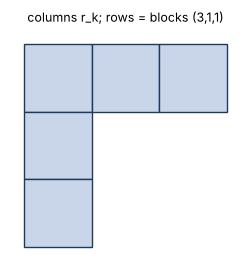

In [3]:
def jordan_matrix(blocks):                 # blocks: list of (eigenvalue, size)
    return sp.diag(*[sp.Matrix(m, m, lambda i, j: lam if i == j else (1 if j == i + 1 else 0)) for lam, m in blocks])

def random_unimodular(n, steps=40):
    P = sp.eye(n)
    for _ in range(steps if n > 1 else 0):
        i, j = rng.choice(n, 2, replace=False)
        P[i, :] = P[i, :] + int(rng.integers(-2, 3)) * P[j, :]
    return P

def jordan_blocks(A, lam):
    n = A.shape[0]; M = A - lam * sp.eye(n)
    dims, P = [0], sp.eye(n)
    while True:
        P = P * M
        d = n - P.rank()
        if d == dims[-1]: break
        dims.append(d)
    r = [dims[k] - dims[k - 1] for k in range(1, len(dims))]          # r_1 >= r_2 >= ...
    return r, [sum(1 for rk in r if rk > i) for i in range(r[0])]     # conjugate partition

J = jordan_matrix([(2, 3), (2, 1), (2, 1), (-1, 2)])
P = random_unimodular(7)
A = P * J * P.inv()
print("A =", A.tolist())
for lam in (2, -1):
    print(f"lambda={lam}: ranks of (A-lambda)^k:", [((A - lam * sp.eye(7))**k).rank() for k in (1, 2, 3)],
          " r =", jordan_blocks(A, lam)[0], " blocks =", jordan_blocks(A, lam)[1])
_, Jsp = A.jordan_form()
print("sympy's Jordan form agrees:", sorted(sp.Matrix(Jsp).diagonal()) == sorted(J.diagonal()) and
      all(sorted(jordan_blocks(Jsp, l)[1]) == sorted(jordan_blocks(J, l)[1]) for l in (2, -1)))
print("mu_A = (X-2)^3 (X+1)^2")

def young(r, ax, title):
    for k, rk in enumerate(r):
        for i in range(rk):
            ax.add_patch(plt.Rectangle((k, -i - 1), 1, 1, fc='#c9d6ea', ec='#1f3a5f'))
    ax.set_xlim(-0.2, len(r) + 0.2); ax.set_ylim(-r[0] - 0.2, 0.2); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=9)

fig, ax = plt.subplots(figsize=(3, 3))
young(jordan_blocks(A, 2)[0], ax, "columns r_k; rows = blocks (3,1,1)")
plt.show()

### P3.3
**How to find it.** Rank is invariant under transposition, and $(A^{\mathsf T}-\lambda)^k=((A-\lambda)^k)^{\mathsf T}$, so the rank sequences coincide automatically; the numerical check is a sanity check of the code. For $S$: if $A=PJP^{-1}$ and $R$ is the block anti-diagonal flip, then $J^{\mathsf T}=RJR$, and $S=PRP^{\mathsf T}$ is symmetric with $S^{-1}AS=P^{-\mathsf T}RJRP^{\mathsf T}=P^{-\mathsf T}J^{\mathsf T}P^{\mathsf T}=A^{\mathsf T}$.

In [4]:
ok = 0
for trial in range(20):
    blocks = [(int(rng.integers(-2, 3)), int(rng.integers(1, 4))) for _ in range(int(rng.integers(1, 4)))]
    J = jordan_matrix(blocks); n = J.shape[0]
    P = random_unimodular(n); A = P * J * P.inv()
    ok += all(((A - l * sp.eye(n))**k).rank() == ((A.T - l * sp.eye(n))**k).rank()
              for l in set(b[0] for b in blocks) for k in range(1, n + 1))
print("same rank sequences:", ok, "/ 20")

blocks = [(1, 3), (1, 1), (-2, 2)]                 # a fixed example for S
J = jordan_matrix(blocks); P = random_unimodular(6); A = P * J * P.inv()
Rflip = sp.diag(*[sp.Matrix(m, m, lambda i, j: 1 if i + j == m - 1 else 0) for _, m in blocks])
assert J.T == Rflip * J * Rflip
S = P * Rflip * P.T
print("S symmetric:", S == S.T, "  S^{-1} A S == A^T:", S.inv() * A * S == A.T, "\nS =", S.tolist())

same rank sequences: 20 / 20
S symmetric: True   S^{-1} A S == A^T: True 
S = [[9562, -3044, 4499, 647, 709, -2877], [-3044, 970, -1433, -205, -224, 913], [4499, -1433, 2117, 304, 333, -1352], [647, -205, 304, 45, 50, -198], [709, -224, 333, 50, 56, -219], [-2877, 913, -1352, -198, -219, 875]]


### P3.4
**How to find it.** The characteristic polynomial of the corner-perturbed block is $X^n-\varepsilon$, so the eigenvalues are the $n$-th roots of $\varepsilon$: a circle of radius $\varepsilon^{1/n}=10^{-1}$. A perturbation of size $10^{-12}$ moved the eigenvalues by $0.1$, which is the whole point of the remark. Random perturbations behave the same way, at radius $\approx(\text{size})^{1/n}$.

eps^(1/n) = 0.10000000000000002   |eigenvalues| in 0.1 ... 0.1


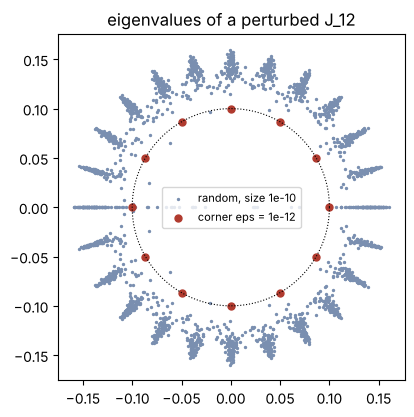

In [5]:
n = 12
J = np.diag(np.ones(n - 1), 1)
E = J.copy(); E[-1, 0] = 1e-12
ev = np.linalg.eigvals(E)
print("eps^(1/n) =", 1e-12 ** (1 / n), "  |eigenvalues| in", np.abs(ev).min().round(4), "...", np.abs(ev).max().round(4))

cloud = np.concatenate([np.linalg.eigvals(J + 1e-10 * rng.standard_normal((n, n))) for _ in range(200)])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(cloud.real, cloud.imag, s=2, c='#7a8fb0', label='random, size 1e-10')
ax.scatter(ev.real, ev.imag, s=25, c='#b03a2e', label='corner eps = 1e-12')
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(0.1 * np.cos(t), 0.1 * np.sin(t), 'k:', lw=0.8)
ax.set_aspect('equal'); ax.legend(fontsize=8); ax.set_title("eigenvalues of a perturbed J_12")
plt.show()

### P3.5
**How to find it.** The series converges for every $A$, but its terms $\|A\|^k/k!$ first grow, peaking near $k=\|A\|$ at about $e^{\|A\|}/\sqrt{2\pi\|A\|}$, so cancellations of huge numbers destroy floating-point accuracy for large norms. `expm` avoids this by scaling and squaring: $e^A=(e^{A/2^s})^{2^s}$ with a Padé approximant for the small matrix.

In [6]:
def expm_series(A, terms=60):
    S = np.eye(len(A)); T = np.eye(len(A))
    for k in range(1, terms):
        T = T @ A / k; S = S + T
    return S

J = jordan_matrix([(sp.Rational(1, 2), 3), (-1, 1)])
P = random_unimodular(4, 10); A = P * J * P.inv()
E_sym = sp.simplify(P * (J.exp()) * P.inv())                  # sympy uses the Jordan formula
An = np.array(A, dtype=float)
E1, E2, E3 = expm_series(An), np.array(E_sym.evalf(), dtype=float), sla.expm(An)
print("series vs Jordan:", np.abs(E1 - E2).max(), "  expm vs Jordan:", np.abs(E3 - E2).max())
print("det e^A =", np.linalg.det(E3), "  e^tr A =", math.exp(np.trace(An)))
t = 0.7
print("rotation:", np.allclose(sla.expm(np.array([[0, -t], [t, 0]])), [[math.cos(t), -math.sin(t)], [math.sin(t), math.cos(t)]]))
A2, B2 = np.array([[0., 1], [0, 0]]), np.array([[0., 0], [1, 0]])
print("e^(A+B) =\n", sla.expm(A2 + B2).round(4), "\ne^A e^B =\n", (sla.expm(A2) @ sla.expm(B2)).round(4))
print("e^A = I with A != 0:", np.allclose(sla.expm(np.array([[0, -2 * np.pi], [2 * np.pi, 0]])), np.eye(2)))

M = 30 * np.array([[0, -1], [1, 0.]])      # norm 30: exact answer is a rotation by 30 radians
logterm = [k * math.log(30) - math.lgamma(k + 1) for k in range(120)]
kmax = int(np.argmax(logterm))
print(f"largest series term ~ {math.exp(logterm[kmax]):.3g} at k = {kmax}")
print("series error with 120 terms:", np.abs(expm_series(M, 120) - sla.expm(M)).max())

series vs Jordan: 3.552713678800501e-15   expm vs Jordan: 8.526512829121202e-14
det e^A = 1.6487212707002965   e^tr A = 1.6487212707001282
rotation: True
e^(A+B) =
 [[1.5431 1.1752]
 [1.1752 1.5431]] 
e^A e^B =
 [[2. 1.]
 [1. 1.]]
e^A = I with A != 0: True
largest series term ~ 7.76e+11 at k = 29
series error with 120 terms: 0.00017816344983911936


With terms of size $10^{12}$ cancelling down to entries of size $1$, double precision (about $16$ digits) keeps only $3$ or $4$ correct digits: the series is mathematically perfect and numerically fragile.

### P3.6
**How to find it.** Over $\mathbb F_2$ there are $2^{n^2}$ matrices, $65536$ for $n=4$: few enough to test all at once if we vectorise. A matrix is nilpotent iff $N^n=0$ (Cayley–Hamilton, since $\chi_N=X^n$). The Jordan type is read off the ranks of $N,N^2,N^3$ over $\mathbb F_2$, which we compute by Gaussian elimination mod $2$.

In [7]:
def all_matrices(n):
    bits = (np.arange(2**(n * n))[:, None] >> np.arange(n * n)) & 1
    return bits.reshape(-1, n, n).astype(np.int64)

def rank_f2(M):
    M = M.copy() % 2; r = 0; rows, cols = M.shape
    for c in range(cols):
        piv = next((i for i in range(r, rows) if M[i, c]), None)
        if piv is None: continue
        M[[r, piv]] = M[[piv, r]]
        for i in range(rows):
            if i != r and M[i, c]: M[i] ^= M[r]
        r += 1
    return r

for n in range(1, 5):
    Ms = all_matrices(n); P = Ms.copy()
    for _ in range(n - 1): P = np.einsum('aij,ajk->aik', P, Ms) % 2
    nil = Ms[(P == 0).all(axis=(1, 2))]
    sq0 = ((np.einsum('aij,ajk->aik', Ms, Ms) % 2) == 0).all(axis=(1, 2)).sum()
    print(f"n={n}: nilpotent {len(nil):5d}   2^(n(n-1)) = {2**(n*(n-1)):5d}   N^2=0: {sq0}")

from collections import Counter
types = Counter()
for N in nil:                                    # n = 4 from the last loop
    ranks = [4] + [rank_f2(np.linalg.matrix_power(N, k) % 2) for k in (1, 2, 3, 4)]
    r = tuple(ranks[k - 1] - ranks[k] for k in range(1, 5) if ranks[k - 1] > ranks[k])
    types[tuple(sum(1 for rk in r if rk > i) for i in range(r[0]))] += 1
print("by Jordan type (block sizes):", dict(sorted(types.items())), " total", sum(types.values()))

n=1: nilpotent     1   2^(n(n-1)) =     1   N^2=0: 1
n=2: nilpotent     4   2^(n(n-1)) =     4   N^2=0: 4
n=3: nilpotent    64   2^(n(n-1)) =    64   N^2=0: 22


n=4: nilpotent  4096   2^(n(n-1)) =  4096   N^2=0: 316


by Jordan type (block sizes): {(1, 1, 1, 1): 1, (2, 1, 1): 105, (2, 2): 210, (3, 1): 1260, (4,): 2520}  total 4096


The total is $4096=2^{12}$, as Fine and Herstein predicted, and the zero matrix is the lonely class $(1,1,1,1)$. The single block $(4)$ is the biggest class: a "generic" nilpotent matrix is one Jordan block, the opposite of the diagonalisable dream. Each class size is $|GL_4(\mathbb F_2)|$ divided by the size of a centraliser, which is how the formula $q^{n(n-1)}$ is proved (see the chapter's references).